# Why Feature Scaling is Required

Feature scaling is the process of transforming numeric features so that they exist on a comparable scale, without distorting the differences in the ranges of values. It is one of the most important — and most frequently skipped — steps in a machine learning pipeline.

**The Problem: Features on Different Scales**

Consider the used_cars_dataset. Some of its numeric columns are:

•	Price — ranges from a few hundred thousand to several million

•	Kilometer — ranges from ~8,500 to over 13,000,000 (outliers present)

•	Mileage_kmpl — ranges roughly from 8 to 21

•	Engine_CC — ranges roughly from 1000 to 3000

•	Power_BHP — ranges roughly from 60 to 210

•	Age_Years — ranges from 1 to 21

•	Seats — ranges from 4 to 7

If these features are fed directly into a distance-based or gradient-based algorithm, Price and Kilometer will completely dominate the calculations simply because their raw numeric magnitude is thousands of times larger than Mileage_kmpl or Seats — even if Mileage_kmpl is just as important, or more important, for the prediction.


**Which Algorithms Need Scaling?**

•	Distance-based algorithms: KNN, K-Means, SVM — these compute Euclidean or other distance metrics, so unscaled features bias the distance toward large-magnitude columns.

•	Gradient-descent-based algorithms: Linear Regression, Logistic Regression, Neural Networks — unscaled features cause slow, unstable convergence.

•	Dimensionality reduction: PCA — the principal components will be dominated by whichever feature has the largest variance in raw units.

•	Regularized models: Ridge, Lasso — the penalty term is applied uniformly, so features must be on the same scale for the penalty to be fair.


**Loading and Inspecting the Dataset**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Load the dataset
df = pd.read_csv("used_cars_dataset.csv")

# Numeric columns that need scaling
numeric_cols = ['Age_Years', 'Price', 'Kilometer', 'Mileage_kmpl',
                 'Engine_CC', 'Power_BHP', 'Seats']

print(df[numeric_cols].describe())


# Standardization — StandardScaler

Standardization rescales a feature so that it has a mean of 0 and a standard deviation of 1. This is also called the Z-score transformation.

The Formula

z = (x − μ) / σ
•	x — the original value
•	μ (mu) — the mean of the feature
•	σ (sigma) — the standard deviation of the feature

When to Use It

•	The feature is approximately normally distributed (bell-shaped), such as Price, Power_BHP, or Engine_CC
•	The algorithm assumes zero-centered data, e.g. PCA, Logistic Regression, Linear Regression, SVM
•	You do not need a strictly bounded range


In [ ]:
scaler_std = StandardScaler()

df_standardized = df.copy()
df_standardized[numeric_cols] = scaler_std.fit_transform(df[numeric_cols])

print(df_standardized[numeric_cols].head())

# Verify: mean should be ~0, std should be ~1
print("\nMean after scaling (~0):\n", df_standardized[numeric_cols].mean())
print("\nStd after scaling (~1):\n", df_standardized[numeric_cols].std())


# Normalization — MinMaxScaler

Normalization rescales a feature into a fixed range, most commonly [0, 1]. It is a linear transformation that preserves the exact shape of the original distribution.

**The Formula**

x′ = (x − xmin) / (xmax − xmin)
•	x — the original value
•	xmin, xmax — the minimum and maximum of the feature
•	x′ — the normalized value, bounded between 0 and 1

**When to Use It**

•	Inputs to neural networks, which often expect bounded input ranges
•	Features with a known, meaningful minimum and maximum, e.g. Seats or Age_Years
•	Image pixel values, percentage-like data, or any feature you want strictly within [0, 1]


In [ ]:
scaler_minmax = MinMaxScaler(feature_range=(0, 1))

df_normalized = df.copy()
df_normalized[numeric_cols] = scaler_minmax.fit_transform(df[numeric_cols])

print(df_normalized[numeric_cols].head())

# Verify: min should be 0, max should be 1
print("\nMin after scaling (0):\n", df_normalized[numeric_cols].min())
print("Max after scaling (1):\n", df_normalized[numeric_cols].max())


# Robust Scaling — RobustScaler

Robust scaling uses the median and the interquartile range (IQR) instead of the mean and standard deviation, making it resistant to outliers — an important property for real-world data like the used_cars_dataset, which contains extreme Kilometer values.

The Formula

x′ = (x − median) / IQR
•	median — the 50th percentile of the feature
•	IQR — the interquartile range, Q3 (75th percentile) minus Q1 (25th percentile)

When to Use It

•	The dataset contains significant outliers, e.g. the Kilometer column in this dataset
•	You want a scaling method that is not distorted by a small number of extreme values
•	You still want an unbounded, roughly centered result (unlike MinMaxScaler)


In [ ]:
scaler_robust = RobustScaler()

df_robust = df.copy()
df_robust[numeric_cols] = scaler_robust.fit_transform(df[numeric_cols])

print(df_robust[numeric_cols].head())


# Summary Comparison Table

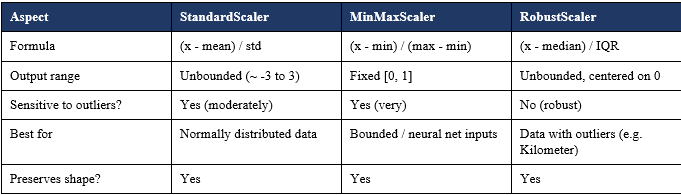